# 5 · Curva de Kuznets ambiental (CKA)

**Hipótesis:** las emisiones por persona suben con el ingreso hasta cierto nivel y luego bajan (U invertida).

$$\ln(CO_2\,pc)_{it} = \alpha_i + \delta_t + \beta_1 \ln(PIB\,pc)_{it} + \beta_2 \ln(PIB\,pc)^2_{it} + \varepsilon_{it}$$

* U invertida ⇔ $\beta_2 < 0$; punto de giro = $\exp(-\beta_1 / 2\beta_2)$.
* $\alpha_i$: efectos fijos por país (geografía, recursos hidro, petróleo…); $\delta_t$: efectos fijos por año (choques comunes como 2009 o 2020).
* Errores **agrupados por país**: 35 años de un mismo país no son 35 datos independientes.
* 18 países × 35 años = 630 observaciones.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from desarrollo_co2 import config, descarga, limpieza, union, desacople as D, kaya, kuznets as K, graficos
from desarrollo_co2.graficos import num   # formato español: 1.234,56

pd.set_option("display.float_format", lambda v: num(v, 2))
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

In [2]:
panel = pd.read_csv(config.PANEL)
d = K.preparar(panel)
print(f"{len(d)} observaciones · {d['iso3'].nunique()} países · PIB pc de {num(d['pib_pc_ppa'].min(), 0)} a {num(d['pib_pc_ppa'].max(), 0)} USD")

630 observaciones · 18 países · PIB pc de 1.172 a 36.395 USD


## 5.1 Cuatro especificaciones + CO2 de consumo

In [3]:
modelos = K.tabla_modelos(panel)
modelos[["modelo", "n", "b1", "b1_p", "b2", "b2_se", "b2_p", "r2", "punto_giro_usd", "pib_pc_max_muestra", "pct_obs_sobre_giro"]]

,modelo,n,b1,b1_p,b2,b2_se,b2_p,r2,punto_giro_usd,pib_pc_max_muestra,pct_obs_sobre_giro
0,MCO agrupado,630,"2,24","0,56","-0,07","0,20","0,75","0,71","23.134.640,33","36.394,92","0,00"
1,EF país,630,"0,75","0,23","-0,01","0,03","0,82","0,96","2.175.654.967.534.346.043.392,00","36.394,92","0,00"
2,EF país + año,630,"0,92","0,04","-0,04","0,03","0,26","0,96","337.811,68","36.394,92","0,00"
3,"EF país + año, cúbico",630,"-8,67","0,45","1,05","1,29","0,42","0,96",NaN,"36.394,92",NaN
4,"EF país + año, CO2 consumo",575,"0,59","0,27","0,00","0,03","0,94","0,78",NaN,"35.872,97",NaN


In [4]:
m = K.ajustar(d, "fe_pais_anio")
pd.DataFrame({"coef": m.params, "error_est": m.bse, "p": m.pvalues, "ic_95_bajo": m.conf_int()[0],
              "ic_95_alto": m.conf_int()[1]}).loc[["x", "x2"]]

,coef,error_est,p,ic_95_bajo,ic_95_alto
x,"0,92","0,44","0,04","0,06","1,78"
x2,"-0,04","0,03","0,26","-0,10","0,03"


**Resultados:**
* El término cuadrático es **negativo pero nunca significativo** (p entre 0,26 y 0,82). Con CO2 de consumo ni siquiera es negativo.
* El punto de giro estimado es absurdo: **USD 338 mil** por persona con efectos fijos país + año (9 veces el país más rico de la muestra), USD 23 millones con MCO agrupado y del orden de 10²¹ con efectos fijos por país.
* **0 %** de las observaciones están por encima del punto de giro: dentro de América Latina la curva no se dobla.
* El modelo cúbico tampoco ayuda (ningún término significativo).

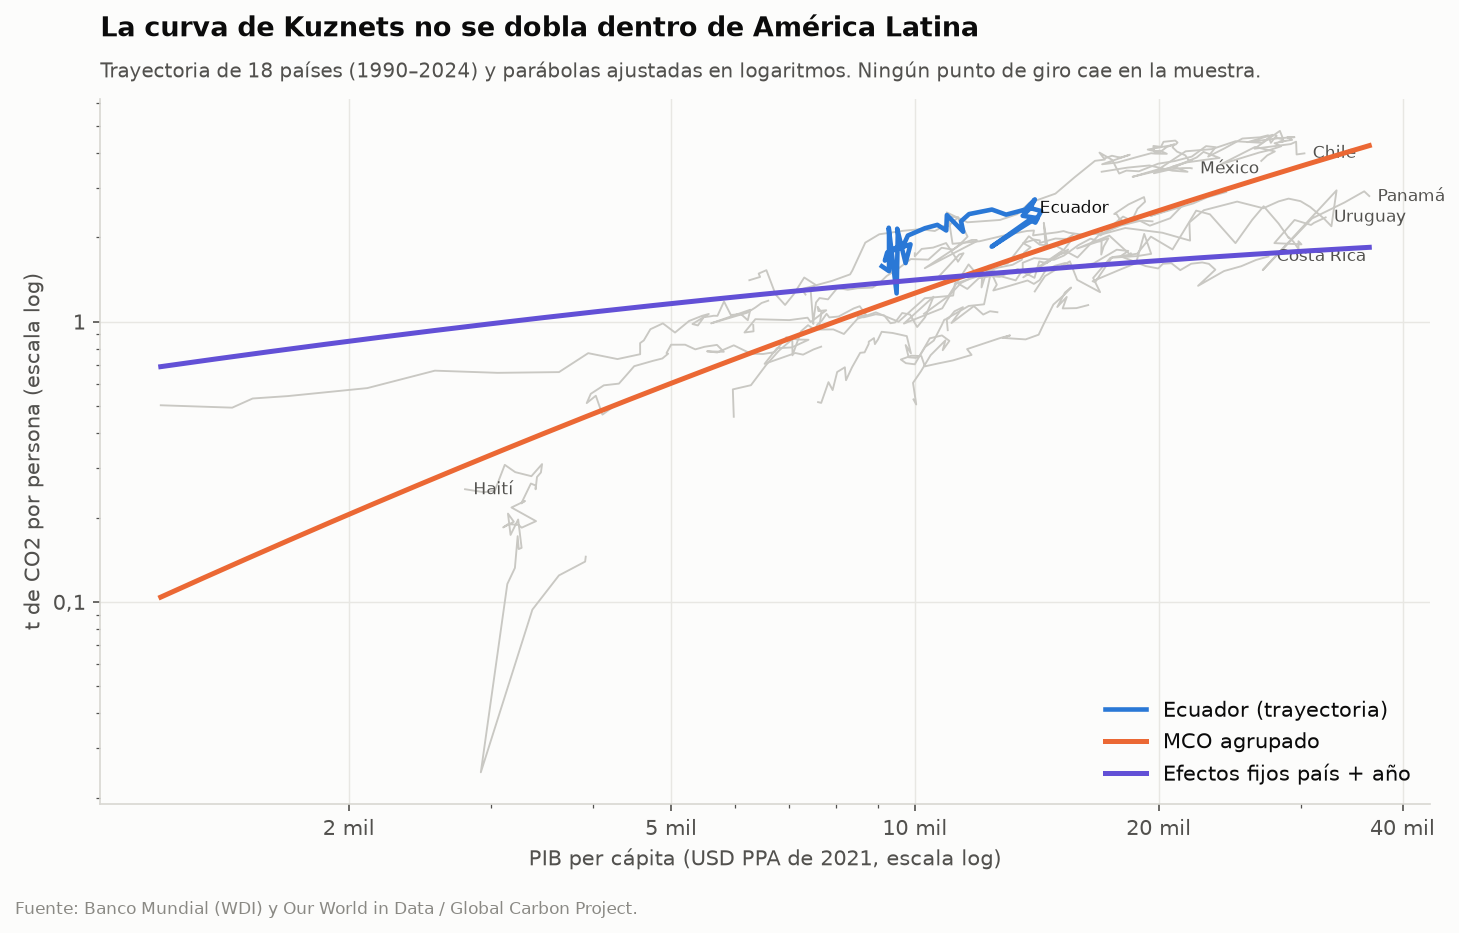

In [5]:
display(Image(config.FIGURAS / "10_kuznets.png"))

## 5.2 ¿Qué tan preciso es el punto de giro? Bootstrap por países

In [6]:
boot = K.bootstrap_punto_giro(d, repeticiones=999)
{k: (num(v, 1) if v < 1e7 else f"{v:.1e}") for k, v in boot.items() if k != "giros"}

{'repeticiones': '999,0',
 'pct_u_invertida': '88,5',
 'giro_mediana': '82.393,4',
 'giro_p05': '8.259,0',
 'giro_p95': '6.0e+18',
 'pct_giro_dentro_muestra': '29,1'}

In [7]:
lg = np.log10(boot["giros"][np.isfinite(boot["giros"])])
pd.Series(lg).describe(percentiles=[.05, .25, .5, .75, .95]).rename("log10(punto de giro, USD)")

count   882,00
mean      7,34
std      10,46
min     -15,91
5%        3,92
25%       4,39
50%       4,91
75%       6,18
95%      18,41
max     171,04
Name: log10(punto de giro, USD), dtype: float64

Se remuestrean **países completos** (999 veces) y se reestima el modelo con efectos fijos país + año.
* En el 88 % de las réplicas sale U invertida (β₂ < 0)… pero el punto de giro va de **USD 8.300 a 6 × 10¹⁸** (percentiles 5–95). La mediana es USD 82 mil, más del doble del máximo observado.
* Que el signo sea "el esperado" no basta: la curvatura es tan leve que el máximo puede estar en cualquier parte. El dato no identifica un punto de giro.

## 5.3 Heterogeneidad: cada país tiene su pendiente

In [8]:
pend = K.pendientes_por_pais(panel)
pend

,iso3,pais,elasticidad,ic_bajo,ic_alto,r2,pib_pc_medio
0,MEX,México,"0,06","-0,31","0,43","0,00","20.060,56"
1,COL,Colombia,"0,29","0,05","0,53","0,25","13.675,19"
2,CRI,Costa Rica,"0,38","0,17","0,60","0,49","17.702,39"
3,DOM,Rep. Dominicana,"0,45","0,27","0,62","0,67","14.251,73"
4,HTI,Haití,"0,49","-3,08","4,06","0,01","3.273,99"
5,HND,Honduras,"0,53","0,47","0,60","0,92","4.709,46"
6,PAN,Panamá,"0,54","0,40","0,68","0,72","21.432,38"
7,ARG,Argentina,"0,55","0,43","0,68","0,73","24.454,96"
8,URY,Uruguay,"0,58","0,41","0,75","0,61","22.705,38"
9,NIC,Nicaragua,"0,62","0,35","0,88","0,60","5.651,36"


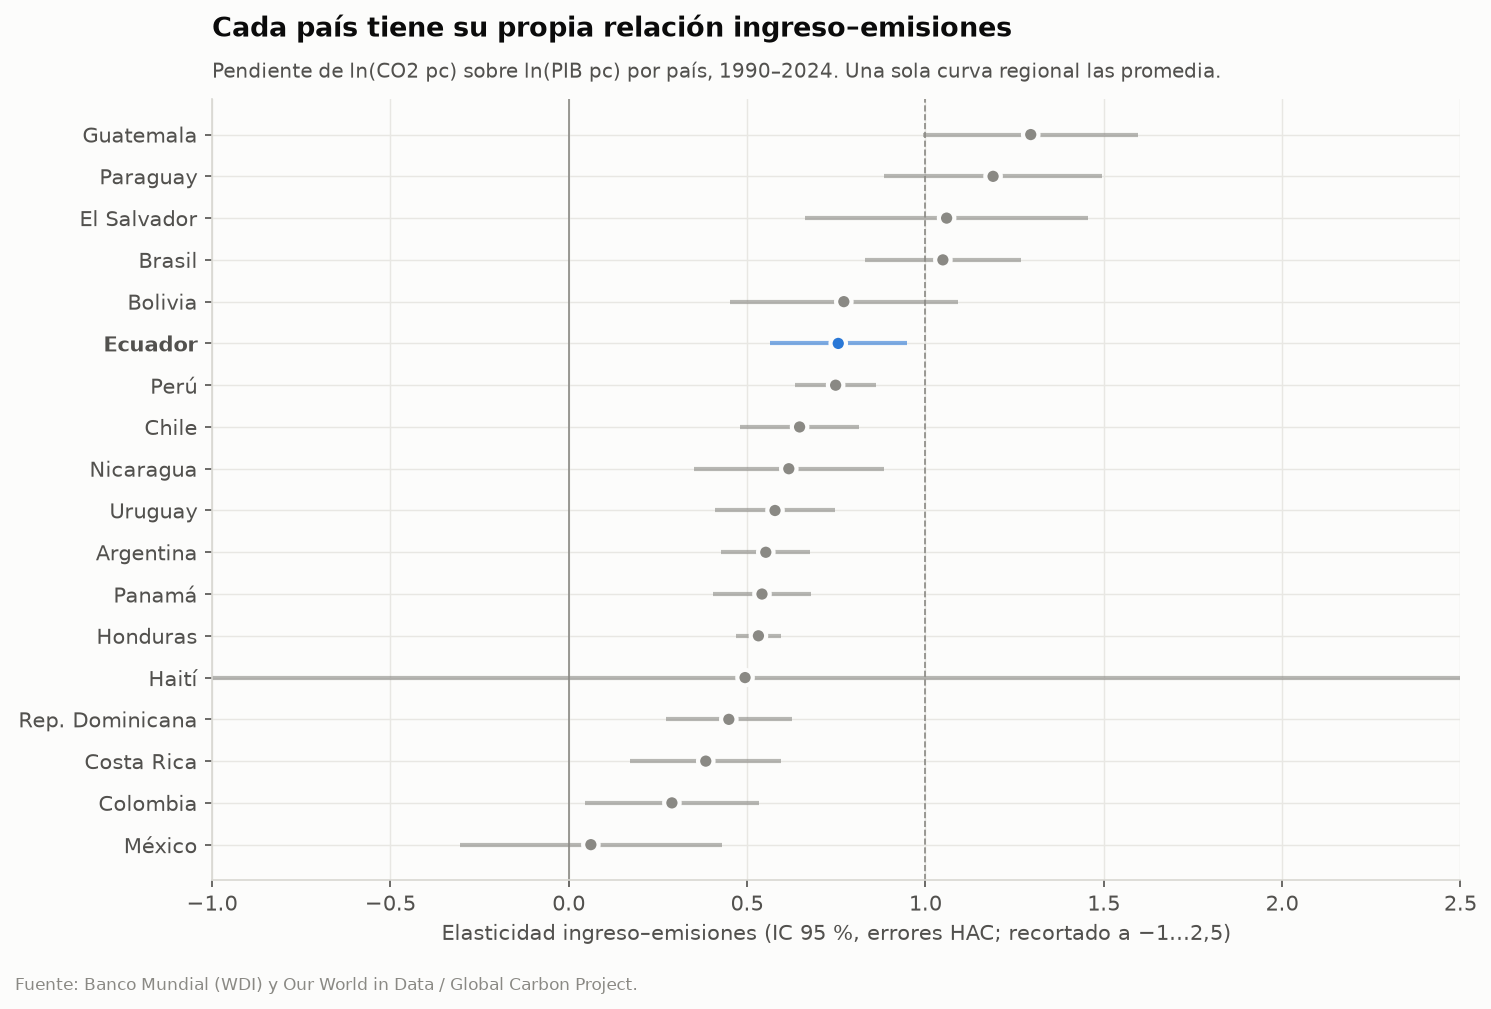

In [9]:
display(Image(config.FIGURAS / "11_kuznets_pendientes.png"))

In [10]:
r = np.corrcoef(np.log(pend["pib_pc_medio"]), pend["elasticidad"])[0, 1]
f"Correlación entre ingreso medio y elasticidad por país: r = {num(r, 2)}"

'Correlación entre ingreso medio y elasticidad por país: r = -0,17'

Si la CKA fuera una ley común, los países más ricos tendrían pendientes menores (más cerca del giro). Las elasticidades van de 0,06 (México) a 1,30 (Guatemala), y casi no se relacionan con el ingreso medio del país (la correlación de abajo es débil). Una sola parábola regional promedia trayectorias muy distintas.

## 5.4 Límites del análisis (y por qué no hay que vender una CKA)

1. **Rango de ingreso corto.** La muestra va de USD 1.200 a 36.000 PPA, casi toda de ingreso medio. Si existe un giro, nada garantiza que caiga dentro de ese rango, y una parábola ajustada solo con la parte creciente no puede ubicarlo.
2. **Correlación, no causalidad.** Crecer no "causa" que las emisiones bajen. Lo que las baja son decisiones (hidroelectricidad, precios de la energía, normas) que se correlacionan con el ingreso en algunos países y en otros no.
3. **Variables omitidas.** La dotación hídrica, ser productor de petróleo, los subsidios a los combustibles o la estructura productiva cambian en el tiempo y no los capturan los efectos fijos. La pobreza o las renovables tienen huecos que impiden usarlas como controles sin perder la mitad del panel.
4. **Series no estacionarias.** ln(PIB) y ln(CO2) tienen tendencia; una regresión en niveles puede salir "significativa" por la tendencia común (regresión espuria). Las pruebas de cointegración en panel van más allá del alcance de este proyecto; los errores agrupados no resuelven ese problema.
5. **Forma funcional.** La parábola obliga a que haya un máximo. Si la relación es cóncava pero creciente (que es lo que se ve), la cuadrática igual "encuentra" un giro lejano y sin sentido.
6. **Fuga de emisiones.** Con CO2 territorial, un país puede bajar emisiones importando bienes intensivos en carbono. Con CO2 de consumo la curvatura desaparece por completo (β₂ = +0,002).
7. **Muestra pequeña de grupos.** 18 países son pocos para errores agrupados (los p-valores son aproximados); el bootstrap por países lo confirma con intervalos enormes.

**Conclusión honesta:** en América Latina 1990–2024 **no hay evidencia de una curva de Kuznets para el CO2**. Las emisiones por persona crecen con el ingreso, aunque cada vez menos que proporcionalmente (elasticidad < 1 en 14 de 18 países). Esperar a "hacerse rico" para que bajen no es una estrategia que los datos respalden: los casos de baja intensidad (Costa Rica, Uruguay, Paraguay en electricidad) son resultado de su matriz eléctrica, no de su nivel de ingreso.